# Proyecto Sigma: Predicción de Cancelación de Clientes en Interconnect

## Descripción del proyecto

Interconnect, un operador de telecomunicaciones, busca reducir la pérdida de clientes mediante estrategias de retención más efectivas. Dado que conservar un cliente existente suele ser menos costoso que adquirir uno nuevo, la compañía desea identificar de manera anticipada a los usuarios con mayor probabilidad de cancelar sus servicios.

El objetivo de este proyecto es desarrollar un modelo de aprendizaje automático capaz de predecir si un cliente abandonará la compañía a partir de información contractual, demográfica y de los servicios contratados.

## Objetivos

- Integrar la información proveniente de múltiples fuentes de datos.
- Construir la variable objetivo a partir del estado del contrato de cada cliente.
- Realizar un análisis exploratorio para identificar patrones relacionados con la cancelación.
- Entrenar y comparar distintos modelos de clasificación.
- Seleccionar el modelo con mejor capacidad predictiva utilizando métricas adecuadas para el problema.

## Datos disponibles

El análisis utiliza información procedente de cuatro tablas:

- **contract:** información contractual y de facturación.
- **personal:** características demográficas de los clientes.
- **internet:** servicios de internet contratados.
- **phone:** servicios telefónicos contratados.

## Pregunta de negocio

**¿Es posible identificar con anticipación a los clientes con mayor probabilidad de abandonar Interconnect para implementar acciones de retención oportunas?**

In [1]:
import pandas as pd

contrato = pd.read_csv("/content/contract.csv")

internet = pd.read_csv("/content/internet.csv")

demografía = pd.read_csv("/content/personal.csv")

telefonía = pd.read_csv("/content/phone.csv")

In [2]:
contrato.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
dtypes: float64(1), object(7)
memory usage: 440.3+ KB


In [3]:
columnas_fechas_contrato = ["BeginDate", "EndDate"]
contrato[columnas_fechas_contrato] = contrato[columnas_fechas_contrato].apply(pd.to_datetime, errors = "coerce")

print(contrato.isna().sum())

customerID             0
BeginDate              0
EndDate             5174
Type                   0
PaperlessBilling       0
PaymentMethod          0
MonthlyCharges         0
TotalCharges           0
dtype: int64


/tmp/ipykernel_1409/2180836271.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  contrato[columnas_fechas_contrato] = contrato[columnas_fechas_contrato].apply(pd.to_datetime, errors = "coerce")


In [4]:
contrato["TotalCharges"] = pd.to_numeric(contrato["TotalCharges"], errors = "coerce")
print(contrato.isna().sum())

customerID             0
BeginDate              0
EndDate             5174
Type                   0
PaperlessBilling       0
PaymentMethod          0
MonthlyCharges         0
TotalCharges          11
dtype: int64


In [5]:
proporcion = contrato["TotalCharges"].isna().sum() / len(contrato) * 100
print(proporcion)

0.1561834445548772


In [6]:
contrato = contrato.dropna(subset = ["TotalCharges"])
print(contrato.info())

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customerID        7032 non-null   object        
 1   BeginDate         7032 non-null   datetime64[ns]
 2   EndDate           1869 non-null   datetime64[ns]
 3   Type              7032 non-null   object        
 4   PaperlessBilling  7032 non-null   object        
 5   PaymentMethod     7032 non-null   object        
 6   MonthlyCharges    7032 non-null   float64       
 7   TotalCharges      7032 non-null   float64       
dtypes: datetime64[ns](2), float64(2), object(4)
memory usage: 494.4+ KB
None


In [7]:
print(contrato.info())
print()
print()
print(contrato.head(5))
print()
print()
print(contrato.isna().sum())
print()
print()
print(contrato.duplicated().sum())
print()
print()
print(contrato.describe(include = "object"))
print()
print()
print(contrato["MonthlyCharges"].describe())

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customerID        7032 non-null   object        
 1   BeginDate         7032 non-null   datetime64[ns]
 2   EndDate           1869 non-null   datetime64[ns]
 3   Type              7032 non-null   object        
 4   PaperlessBilling  7032 non-null   object        
 5   PaymentMethod     7032 non-null   object        
 6   MonthlyCharges    7032 non-null   float64       
 7   TotalCharges      7032 non-null   float64       
dtypes: datetime64[ns](2), float64(2), object(4)
memory usage: 494.4+ KB
None


   customerID  BeginDate    EndDate            Type PaperlessBilling  \
0  7590-VHVEG 2020-01-01        NaT  Month-to-month              Yes   
1  5575-GNVDE 2017-04-01        NaT        One year               No   
2  3668-QPYBK 2019-10-01 2019-12-01  Month-to-month            

In [8]:
print(internet.info())
print()
print()
print(internet.head(5))
print()
print()
print(internet.isna().sum())
print()
print()
print(internet.duplicated().sum())
print()
print()
print(internet.describe(include = "object"))
print()
print()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5517 entries, 0 to 5516
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   customerID        5517 non-null   object
 1   InternetService   5517 non-null   object
 2   OnlineSecurity    5517 non-null   object
 3   OnlineBackup      5517 non-null   object
 4   DeviceProtection  5517 non-null   object
 5   TechSupport       5517 non-null   object
 6   StreamingTV       5517 non-null   object
 7   StreamingMovies   5517 non-null   object
dtypes: object(8)
memory usage: 344.9+ KB
None


   customerID InternetService OnlineSecurity OnlineBackup DeviceProtection  \
0  7590-VHVEG             DSL             No          Yes               No   
1  5575-GNVDE             DSL            Yes           No              Yes   
2  3668-QPYBK             DSL            Yes          Yes               No   
3  7795-CFOCW             DSL            Yes           No              Ye

En este conjunto de datos de servicios de internet no se identificaron valores faltantes, registros duplicados ni inconsistencias evidentes en los tipos de datos. Todas las variables presentan información completa para los 5.517 clientes incluidos en el dataset. Adicionalmente, las variables categóricas contienen únicamente las categorías esperadas, sin registros anómalos o etiquetas sospechosas. Se observa que los servicios adicionales, como seguridad en línea, respaldo en línea, protección de dispositivos, soporte técnico y servicios de streaming, muestran una distribución relativamente equilibrada entre clientes que los contratan y clientes que no, lo que sugiere una adecuada representación de ambos grupos para análisis posteriores. Debido a ello, no fue necesario realizar transformaciones o correcciones adicionales en esta etapa y el conjunto de datos se considera apto para continuar con el proceso de integración y análisis.

In [9]:
print(demografía.info())
print()
print()
print(demografía.head(5))
print()
print()
print(demografía.isna().sum())
print()
print()
print(demografía.duplicated().sum())
print()
print()
print(demografía.describe(include = "object"))
print()
print()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     7043 non-null   object
 1   gender         7043 non-null   object
 2   SeniorCitizen  7043 non-null   int64 
 3   Partner        7043 non-null   object
 4   Dependents     7043 non-null   object
dtypes: int64(1), object(4)
memory usage: 275.2+ KB
None


   customerID  gender  SeniorCitizen Partner Dependents
0  7590-VHVEG  Female              0     Yes         No
1  5575-GNVDE    Male              0      No         No
2  3668-QPYBK    Male              0      No         No
3  7795-CFOCW    Male              0      No         No
4  9237-HQITU  Female              0      No         No


customerID       0
gender           0
SeniorCitizen    0
Partner          0
Dependents       0
dtype: int64


0


        customerID gender Partner Dependents
count         7043   7043    7043    

En el conjunto de datos demográficos no se identificaron valores faltantes, registros duplicados ni inconsistencias evidentes en los tipos de datos. Cada cliente cuenta con un identificador único y las variables categóricas presentan únicamente las categorías esperadas. La distribución de género y estado de pareja se encuentra relativamente equilibrada, mientras que la mayoría de los clientes no reporta dependientes. Debido a que no se detectaron problemas de calidad de datos ni transformaciones necesarias para esta etapa, el dataset se considera listo para su integración con las demás fuentes de información del proyecto.

In [10]:
print(telefonía.info())
print()
print()
print(telefonía.head(5))
print()
print()
print(telefonía.isna().sum())
print()
print()
print(telefonía.duplicated().sum())
print()
print()
print(telefonía.describe(include = "object"))
print()
print()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6361 entries, 0 to 6360
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     6361 non-null   object
 1   MultipleLines  6361 non-null   object
dtypes: object(2)
memory usage: 99.5+ KB
None


   customerID MultipleLines
0  5575-GNVDE            No
1  3668-QPYBK            No
2  9237-HQITU            No
3  9305-CDSKC           Yes
4  1452-KIOVK           Yes


customerID       0
MultipleLines    0
dtype: int64


0


        customerID MultipleLines
count         6361          6361
unique        6361             2
top     5575-GNVDE            No
freq             1          3390




En el conjunto de datos de telefonía no se identificaron valores faltantes, registros duplicados ni inconsistencias en los tipos de datos. Cada cliente posee un identificador único y la variable MultipleLines contiene únicamente las categorías esperadas, indicando si el cliente cuenta o no con múltiples líneas telefónicas. La distribución entre ambas categorías es relativamente equilibrada, por lo que no se observan anomalías ni problemas de calidad que requieran corrección. Debido a ello, el dataset se considera listo para su integración con las demás fuentes de información del proyecto.

In [11]:
dataset = pd.merge(contrato, internet, on = "customerID", how = "outer")
dataset = pd.merge(dataset, demografía, on = "customerID", how = "outer")
dataset = pd.merge(dataset, telefonía, on = "customerID", how = "outer")

In [12]:
print(dataset.info())
print()
print()
print(dataset.head(5))
print()
print()
print(dataset.isna().sum())
print()
print()
print(dataset.duplicated().sum())
print()
print()
print(dataset.describe(include = "object"))
print()
print()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customerID        7043 non-null   object        
 1   BeginDate         7032 non-null   datetime64[ns]
 2   EndDate           1869 non-null   datetime64[ns]
 3   Type              7032 non-null   object        
 4   PaperlessBilling  7032 non-null   object        
 5   PaymentMethod     7032 non-null   object        
 6   MonthlyCharges    7032 non-null   float64       
 7   TotalCharges      7032 non-null   float64       
 8   InternetService   5517 non-null   object        
 9   OnlineSecurity    5517 non-null   object        
 10  OnlineBackup      5517 non-null   object        
 11  DeviceProtection  5517 non-null   object        
 12  TechSupport       5517 non-null   object        
 13  StreamingTV       5517 non-null   object        
 14  StreamingMovies   5517 n

In [13]:
columnas = ["InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

dataset[columnas] = dataset[columnas].fillna("No tomó el servicio")

In [14]:
columnas = ["MonthlyCharges", "TotalCharges"]

dataset[columnas] = dataset[columnas].fillna(0)

In [15]:
dataset["Type"] = dataset["Type"].fillna("Sin contrato")

In [16]:
dataset["PaperlessBilling"] = dataset["PaperlessBilling"].fillna("Sin facturación electrónica")

In [17]:
dataset["PaymentMethod"] = dataset["PaymentMethod"].fillna("No aplica")

In [18]:
dataset["MultipleLines"] = dataset["MultipleLines"].fillna("No aplica")

In [19]:
dataset.isna().sum()

,0
customerID,0
BeginDate,11
EndDate,5174
Type,0
PaperlessBilling,0
PaymentMethod,0
MonthlyCharges,0
TotalCharges,0
InternetService,0
OnlineSecurity,0


In [20]:
print(dataset.info())
print()
print()
print(dataset.head(5))
print()
print()
print(dataset.isna().sum())
print()
print()
print(dataset.duplicated().sum())
print()
print()
print(dataset.describe(include = "object"))
print()
print()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customerID        7043 non-null   object        
 1   BeginDate         7032 non-null   datetime64[ns]
 2   EndDate           1869 non-null   datetime64[ns]
 3   Type              7043 non-null   object        
 4   PaperlessBilling  7043 non-null   object        
 5   PaymentMethod     7043 non-null   object        
 6   MonthlyCharges    7043 non-null   float64       
 7   TotalCharges      7043 non-null   float64       
 8   InternetService   7043 non-null   object        
 9   OnlineSecurity    7043 non-null   object        
 10  OnlineBackup      7043 non-null   object        
 11  DeviceProtection  7043 non-null   object        
 12  TechSupport       7043 non-null   object        
 13  StreamingTV       7043 non-null   object        
 14  StreamingMovies   7043 n

Durante la integración de las fuentes de información se combinaron los conjuntos de datos de contratos, servicios de internet, telefonía y datos demográficos utilizando la columna customerID como identificador único de cada cliente. Inicialmente se realizó una unión mediante inner join, lo que redujo el conjunto de datos a 4.832 registros al conservar únicamente los clientes presentes simultáneamente en todas las tablas. Debido a que esta estrategia eliminaba una parte importante de clientes válidos que no necesariamente habían contratado todos los servicios disponibles, se optó por utilizar un outer join, permitiendo conservar el universo completo de 7.043 clientes.

Como resultado de esta unión se generaron valores faltantes que fueron analizados desde la perspectiva del negocio antes de aplicar cualquier transformación. En las variables relacionadas con los servicios de internet (InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV y StreamingMovies), los valores faltantes fueron interpretados como clientes que no contrataron servicios de internet. Por esta razón, dichos registros fueron reemplazados por la categoría "No tomó el servicio", transformando la ausencia de información en una característica explícita del cliente.

De manera similar, los valores faltantes observados en la variable MultipleLines fueron interpretados como clientes que no disponen del servicio correspondiente de telefonía. Al tratarse de una ausencia justificada por la contratación de servicios y no de un error de captura, estos registros se conservaron para mantener la integridad del conjunto de datos.

También se identificaron 11 clientes presentes en la información demográfica pero sin información contractual asociada. Con el fin de preservar estos registros, los valores faltantes de las variables contractuales fueron reemplazados por categorías representativas de su situación. La variable Type fue completada con "Sin contrato", PaperlessBilling con "Sin facturación electrónica" y PaymentMethod con "No aplica". En las variables numéricas MonthlyCharges y TotalCharges se asignó el valor 0, asumiendo que estos clientes no presentan cargos debido a la ausencia de un contrato registrado.

Por otra parte, la variable EndDate presentó 5.174 valores faltantes. Tras analizar el significado de esta columna, se concluyó que dichos valores no corresponden a errores ni a información perdida. La ausencia de una fecha de finalización indica que el cliente mantiene su contrato activo al momento de la recopilación de los datos. Debido a que estos registros representan aproximadamente el 73,5 % de la base de clientes y poseen un significado claro dentro del negocio, se decidió conservarlos sin sustitución ni eliminación. En consecuencia, los valores faltantes de EndDate se interpretarán como contratos vigentes durante las etapas posteriores del análisis.

Gracias a estas decisiones se logró construir un dataset consolidado de 7.043 clientes, preservando la totalidad de la información disponible, minimizando la pérdida de registros y convirtiendo los valores faltantes en información de negocio explícita y útil para las etapas de análisis exploratorio, ingeniería de características y modelado predictivo.

In [21]:
dataset["Fuga"] = dataset["EndDate"].notna()

In [22]:
columnas_categoricas = [
    "Type",
    "PaperlessBilling",
    "PaymentMethod",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "gender",
    "Partner",
    "Dependents",
    "MultipleLines"
]

for columna in columnas_categoricas:
    print(f"\n{'=' * 50}")
    print(columna)
    tabla_contingencia = pd.crosstab(dataset[columna], dataset["Fuga"], normalize = "index") * 100
    print(tabla_contingencia)



Type
Fuga                 False      True 
Type                                 
Month-to-month   57.290323  42.709677
One year         88.722826  11.277174
Sin contrato    100.000000   0.000000
Two year         97.151335   2.848665

PaperlessBilling
Fuga                              False      True 
PaperlessBilling                                  
No                            83.624302  16.375698
Sin facturación electrónica  100.000000   0.000000
Yes                           66.410749  33.589251

PaymentMethod
Fuga                            False      True 
PaymentMethod                                   
Bank transfer (automatic)   83.268482  16.731518
Credit card (automatic)     84.746877  15.253123
Electronic check            54.714588  45.285412
Mailed check                80.798005  19.201995
No aplica                  100.000000   0.000000

InternetService
Fuga                     False      True 
InternetService                          
DSL                  81.040892  18

In [23]:
resultados = []

for columna in columnas_categoricas:

    tabla = pd.crosstab(
        dataset[columna],
        dataset["Fuga"],
        normalize="index"
    ) * 100

    diferencia = tabla[True].max() - tabla[True].min()

    resultados.append(
        {
            "Variable": columna,
            "Diferencia": diferencia
        }
    )

ranking = pd.DataFrame(resultados)

ranking.sort_values(
    by="Diferencia",
    ascending=False
)

,Variable,Diferencia
2,PaymentMethod,45.285412
0,Type,42.709677
3,InternetService,34.487785
4,OnlineSecurity,34.361744
7,TechSupport,34.230493
1,PaperlessBilling,33.589251
5,OnlineBackup,32.523776
6,DeviceProtection,31.722645
9,StreamingMovies,26.275451
8,StreamingTV,26.118151


In [24]:
top_5 = ranking.sort_values(
    by="Diferencia",
    ascending=False
).head()

Con el objetivo de identificar las variables categóricas con mayor asociación a la fuga de clientes, se calculó para cada variable la diferencia entre la categoría con la mayor tasa de abandono y la categoría con la menor tasa de abandono. Este enfoque permitió cuantificar la capacidad de cada variable para discriminar entre clientes que permanecen y clientes que cancelan el servicio. Los resultados muestran que el método de pago, el tipo de contrato, el tipo de servicio de internet, la seguridad en línea y el soporte técnico presentan las diferencias más altas en las tasas de fuga, lo que sugiere una fuerte relación con la probabilidad de cancelación. En contraste, variables como género y múltiples líneas telefónicas exhibieron diferencias mínimas, indicando una influencia reducida sobre el abandono de clientes. Estos resultados permitieron priorizar las variables con mayor potencial explicativo para las siguientes etapas del análisis y la construcción de modelos predictivos.

In [25]:
top_5.head()

,Variable,Diferencia
2,PaymentMethod,45.285412
0,Type,42.709677
3,InternetService,34.487785
4,OnlineSecurity,34.361744
7,TechSupport,34.230493


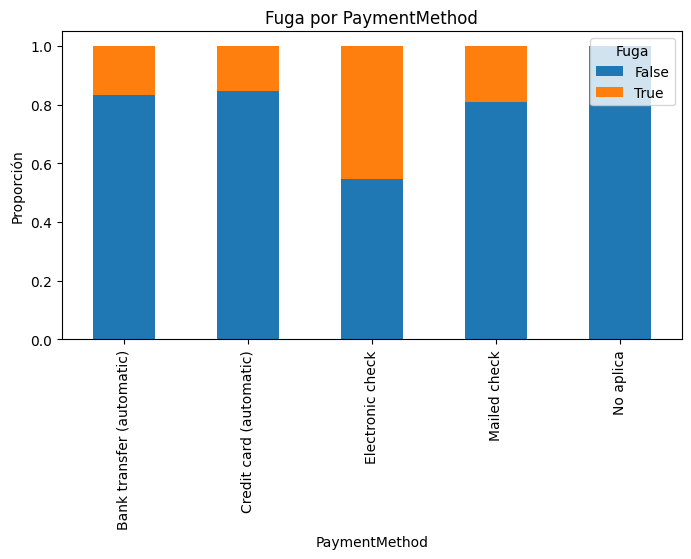

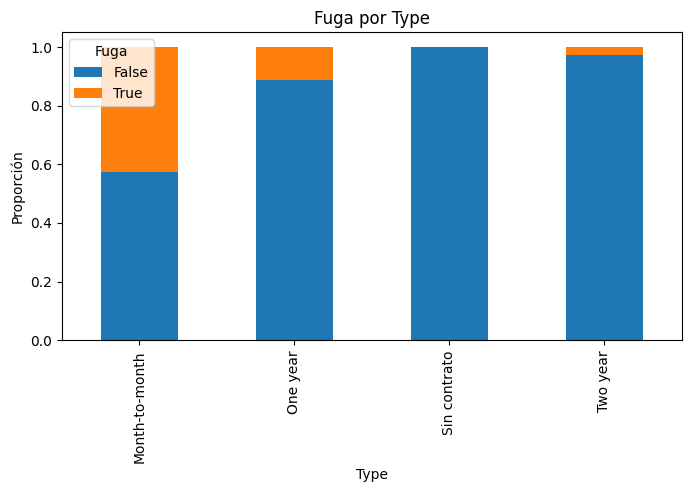

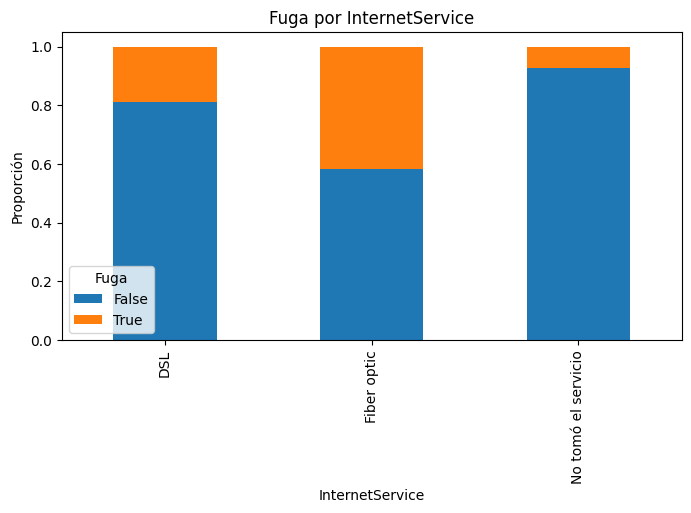

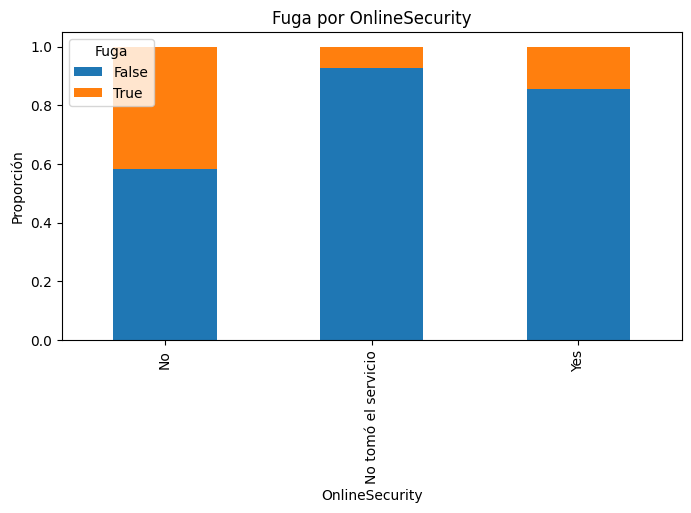

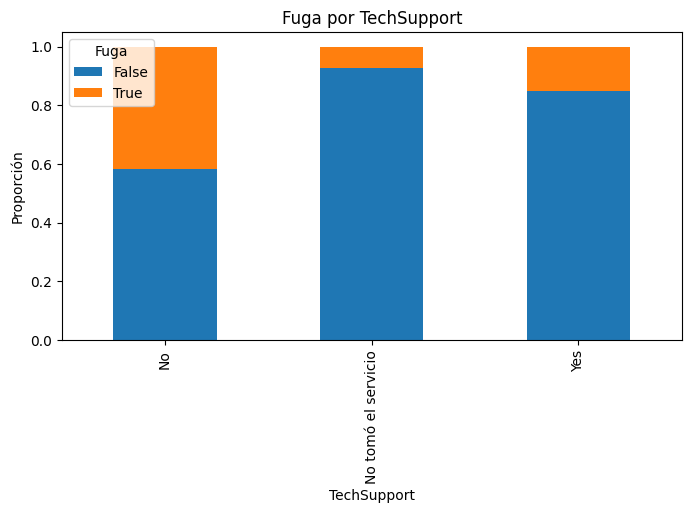

In [26]:
import matplotlib.pyplot as plt

for columna in top_5["Variable"]:

    pd.crosstab(
        dataset[columna],
        dataset["Fuga"],
        normalize="index"
    ).plot(
        kind="bar",
        stacked=True,
        figsize=(8, 4)
    )

    plt.title(f"Fuga por {columna}")
    plt.ylabel("Proporción")
    plt.xlabel(columna)

    plt.show()

Para identificar las variables categóricas con mayor capacidad explicativa respecto a la fuga de clientes, se calculó una métrica basada en la diferencia entre la tasa máxima y mínima de abandono observada entre las categorías de cada variable. Cuanto mayor es esta diferencia, mayor es la capacidad de la variable para distinguir entre clientes con alta y baja probabilidad de cancelar el servicio.

Los resultados muestran que PaymentMethod presentó la mayor diferencia observada (45.29 puntos porcentuales), seguida por Type (42.71 puntos porcentuales). A continuación se ubicaron InternetService (34.49 puntos porcentuales), OnlineSecurity (34.36 puntos porcentuales) y TechSupport (34.23 puntos porcentuales). Estas cinco variables conforman el grupo de características categóricas con la asociación más fuerte con la variable objetivo Fuga.

In [27]:
dataset.groupby("Fuga")[
    ["MonthlyCharges", "TotalCharges"]
].describe()

MonthlyCharges                                                           \
               count       mean        std    min    25%    50%   75%     max   
Fuga                                                                            
False         5174.0  61.177068  31.189596   0.00  25.05  64.40  88.4  118.75   
True          1869.0  74.441332  24.666053  18.85  56.15  79.65  94.2  118.35   

      TotalCharges                                                             \
             count         mean          std    min    25%       50%      75%   
Fuga                                                                            
False       5174.0  2549.911442  2329.954215   0.00  572.9  1679.525  4262.85   
True        1869.0  1531.796094  1890.822994  18.85  134.5   703.550  2331.30   

                
           max  
Fuga            
False  8672.45  
True   8684.80

Para complementar el análisis de las variables categóricas, se estudió el comportamiento de los cargos mensuales y los cargos totales en función de la fuga de clientes. Los resultados muestran que los clientes que abandonaron la compañía presentan un cargo mensual promedio superior al de los clientes que permanecen activos, lo que sugiere una posible relación entre facturas mensuales elevadas y una mayor probabilidad de cancelación. Por otro lado, los clientes que continúan en la compañía acumulan cargos totales considerablemente más altos, tanto en términos de media como de mediana. Este comportamiento indica que los clientes con mayor permanencia generan un volumen acumulado de facturación más elevado, mientras que aquellos que abandonan suelen hacerlo tras un período relativamente más corto de relación con la empresa. Estos resultados refuerzan la importancia de las variables económicas dentro de la explicación del comportamiento de fuga observado en el conjunto de datos.

In [28]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customerID        7043 non-null   object        
 1   BeginDate         7032 non-null   datetime64[ns]
 2   EndDate           1869 non-null   datetime64[ns]
 3   Type              7043 non-null   object        
 4   PaperlessBilling  7043 non-null   object        
 5   PaymentMethod     7043 non-null   object        
 6   MonthlyCharges    7043 non-null   float64       
 7   TotalCharges      7043 non-null   float64       
 8   InternetService   7043 non-null   object        
 9   OnlineSecurity    7043 non-null   object        
 10  OnlineBackup      7043 non-null   object        
 11  DeviceProtection  7043 non-null   object        
 12  TechSupport       7043 non-null   object        
 13  StreamingTV       7043 non-null   object        
 14  StreamingMovies   7043 n

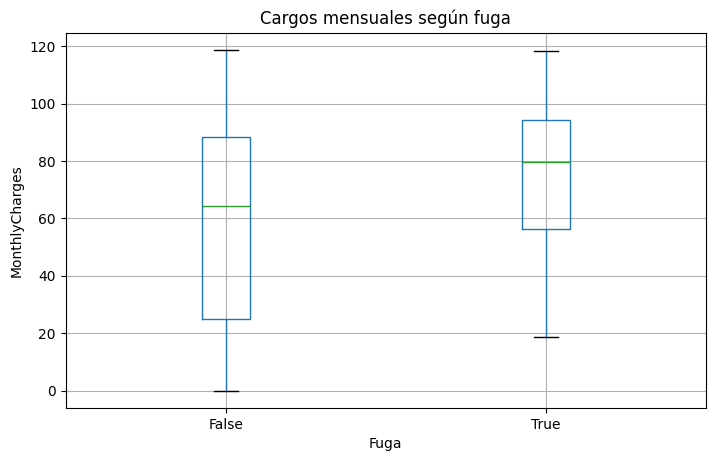

In [29]:
import matplotlib.pyplot as plt

dataset.boxplot(
    column="MonthlyCharges",
    by="Fuga",
    figsize=(8, 5)
)

plt.title("Cargos mensuales según fuga")
plt.suptitle("")
plt.xlabel("Fuga")
plt.ylabel("MonthlyCharges")
plt.show()

El análisis de los cargos mensuales revela diferencias entre los clientes que permanecen en la compañía y aquellos que cancelan el servicio. Los clientes que presentan fuga registran valores de facturación mensual generalmente más elevados que los clientes que continúan activos, lo que sugiere una posible relación entre el costo mensual del servicio y la probabilidad de abandono. Aunque existe solapamiento entre ambos grupos, los resultados indican que MonthlyCharges podría constituir una variable relevante para explicar y predecir la fuga de clientes, por lo que será considerada en las etapas posteriores de modelado.

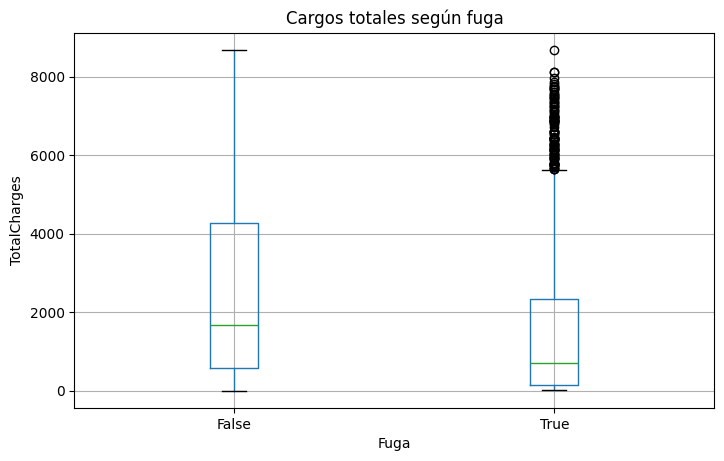

In [30]:
dataset.boxplot(
    column="TotalCharges",
    by="Fuga",
    figsize=(8, 5)
)

plt.title("Cargos totales según fuga")
plt.suptitle("")
plt.xlabel("Fuga")
plt.ylabel("TotalCharges")
plt.show()

El análisis de los cargos totales muestra diferencias entre los clientes que permanecen en la compañía y aquellos que presentan fuga. Los clientes que continúan activos acumulan cargos totales considerablemente más altos que los clientes que cancelan el servicio, lo que sugiere una relación entre la permanencia en la empresa y el volumen de facturación acumulada. Por el contrario, los clientes que abandonan tienden a concentrarse en niveles inferiores de cargos totales, aunque existe un grupo reducido que alcanzó valores elevados antes de cancelar el servicio. Estos resultados indican que TotalCharges constituye una variable potencialmente relevante para caracterizar el comportamiento de permanencia y abandono dentro de la cartera de clientes.

In [31]:
caracteristicas = dataset.drop(columns = ["Fuga", "EndDate", "customerID", "BeginDate"], axis = 1)

objetivo = dataset["Fuga"]

In [32]:
from sklearn.model_selection import train_test_split

caracteristicas_entrenamiento, caracteristicas_prueba, objetivo_entrenamiento, objetivo_prueba = train_test_split(caracteristicas, objetivo, random_state = 12345, shuffle = True, test_size = 0.4, stratify = objetivo)
caracteristicas_validacion, caracteristicas_prueba, objetivo_validacion, objetivo_prueba = train_test_split(caracteristicas_prueba, objetivo_prueba, test_size = 0.5, random_state = 12345, shuffle = True, stratify = objetivo_prueba)

Fuga
False    73.463013
True     26.536987
Name: proportion, dtype: float64


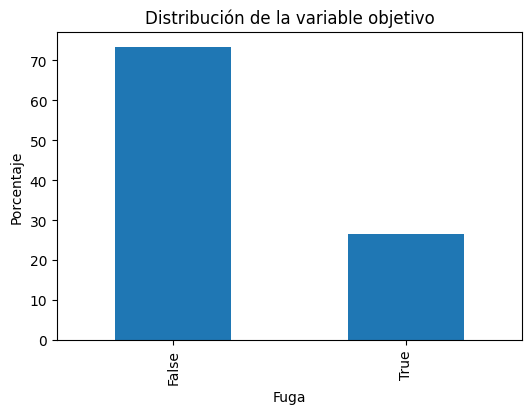

In [33]:
import matplotlib.pyplot as plt

desbalance_de_clases = objetivo.value_counts(normalize=True) * 100

print(desbalance_de_clases)

desbalance_de_clases.plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Distribución de la variable objetivo")
plt.ylabel("Porcentaje")
plt.xlabel("Fuga")
plt.show()

In [34]:
from sklearn.utils import shuffle
from sklearn.utils import resample

dataset_entrenamiento = caracteristicas_entrenamiento.copy()

dataset_entrenamiento["Fuga"] = objetivo_entrenamiento

dataset_True_entrenamiento = dataset_entrenamiento[dataset_entrenamiento["Fuga"] == True]
dataset_False_entrenamiento = dataset_entrenamiento[dataset_entrenamiento["Fuga"] == False]

dataset_True_sobremuestreado = resample(dataset_True_entrenamiento, replace = True, random_state = 12345, n_samples = len(dataset_False_entrenamiento))

dataset_entrenamiento_sobremuestreado = pd.concat([dataset_True_sobremuestreado, dataset_False_entrenamiento])
dataset_entrenamiento_sobremuestreado = shuffle(dataset_entrenamiento_sobremuestreado, random_state = 12345)

caracteristicas_entrenamiento_sobremuestreado = dataset_entrenamiento_sobremuestreado.drop(["Fuga"], axis = 1)
objetivo_entrenamiento_sobremuestreado = dataset_entrenamiento_sobremuestreado["Fuga"]


Fuga
True     50.0
False    50.0
Name: proportion, dtype: float64


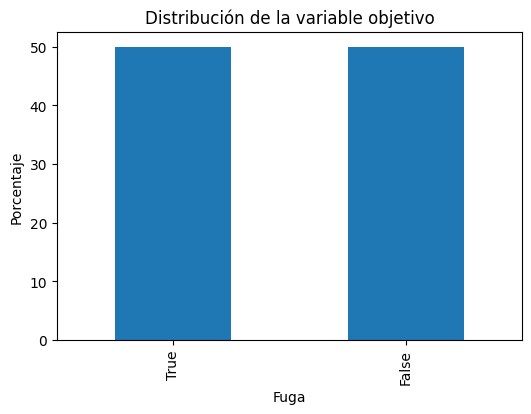

In [35]:
import matplotlib.pyplot as plt

desbalance_de_clases = objetivo_entrenamiento_sobremuestreado.value_counts(normalize=True) * 100

print(desbalance_de_clases)

desbalance_de_clases.plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Distribución de la variable objetivo")
plt.ylabel("Porcentaje")
plt.xlabel("Fuga")
plt.show()

Antes de iniciar el entrenamiento de los modelos, se analizó la distribución de la variable objetivo Fuga con el fin de identificar posibles problemas de desbalance de clases. Los resultados mostraron que aproximadamente el 73.46 % de los clientes pertenecía a la categoría de permanencia (False), mientras que el 26.54 % correspondía a clientes que cancelaron el servicio (True). Esta distribución evidencia un desequilibrio moderado que podría sesgar el aprendizaje de algunos algoritmos hacia la clase mayoritaria.

Con el objetivo de reducir este efecto, se aplicó una técnica de sobremuestreo (oversampling) sobre el conjunto de entrenamiento. Para ello, se separaron los registros de la clase minoritaria y la clase mayoritaria, y posteriormente se utilizó la función resample() de Scikit-Learn para generar observaciones adicionales de la clase minoritaria mediante muestreo con reemplazo. La cantidad de observaciones generadas se ajustó hasta igualar el tamaño de la clase mayoritaria.

Una vez realizado el sobremuestreo, ambas clases quedaron representadas en proporciones equivalentes dentro del conjunto de entrenamiento, alcanzando una distribución cercana al 50 % para cada categoría. Posteriormente, los datos fueron mezclados aleatoriamente mediante la función shuffle() para evitar que los registros de una misma clase quedaran agrupados.

Este procedimiento permitió construir un conjunto de entrenamiento balanceado, reduciendo el riesgo de que los modelos favorezcan sistemáticamente la predicción de la clase mayoritaria y facilitando una evaluación más adecuada de la capacidad de detección de clientes con fuga.

In [36]:
columnas_categoricas = [
    "Type",
    "PaperlessBilling",
    "PaymentMethod",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "gender",
    "Partner",
    "Dependents",
    "MultipleLines"
]

caracteristicas_entrenamiento_sobremuestreado = pd.get_dummies(caracteristicas_entrenamiento_sobremuestreado, columns = columnas_categoricas, drop_first = True)

caracteristicas_prueba = pd.get_dummies(caracteristicas_prueba, columns = columnas_categoricas, drop_first = True)

caracteristicas_validacion = pd.get_dummies(caracteristicas_validacion, columns = columnas_categoricas, drop_first = True)

Una vez balanceado el conjunto de entrenamiento, se procedió a transformar las variables categóricas a un formato numérico mediante la técnica One-Hot Encoding (OHE). Este proceso fue necesario debido a que la mayoría de los algoritmos de aprendizaje automático no pueden trabajar directamente con variables de texto.

Modelo base

El área bajo la curva ROC es de: 0.5
La sensibilidad del modelo base es de:  0.0


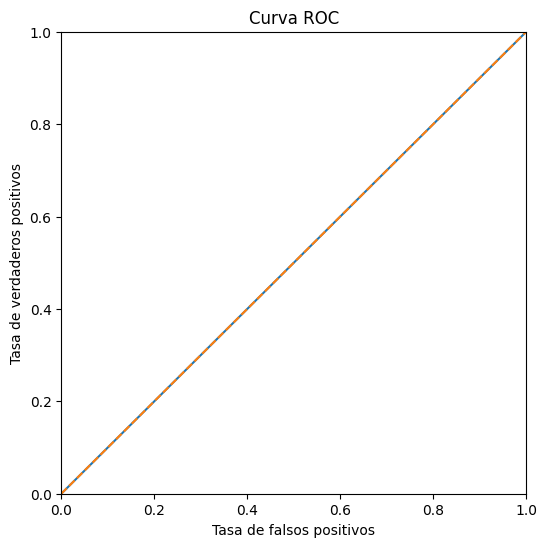

In [37]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.metrics import recall_score

modelo_base = DummyClassifier(strategy = "most_frequent")

modelo_base.fit(caracteristicas_entrenamiento_sobremuestreado, objetivo_entrenamiento_sobremuestreado)

prediccion_base = modelo_base.predict(caracteristicas_prueba)

sensibilidad_base = recall_score(objetivo_prueba, prediccion_base)



probabilities_valid_linear_dummy = modelo_base.predict_proba(caracteristicas_validacion)
probabilities_one_valid_linear_dummy = probabilities_valid_linear_dummy[:, 1]
auc_roc_linear_dummy = roc_auc_score(objetivo_validacion, probabilities_one_valid_linear_dummy)

print("El área bajo la curva ROC es de:", auc_roc_linear_dummy)
print("La sensibilidad del modelo base es de: ", sensibilidad_base)

fpr, tpr, thresholds = roc_curve(objetivo_validacion, probabilities_one_valid_linear_dummy)

plt.figure(figsize = (6, 6))
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.ylabel('Tasa de verdaderos positivos')
plt.xlabel('Tasa de falsos positivos')
plt.title('Curva ROC')
plt.show()


Modelo base (Dummy Classifier)

Como punto de partida para el proceso de modelado se construyó un modelo base utilizando DummyClassifier con la estrategia most_frequent. Este modelo no aprende patrones a partir de las variables disponibles y simplemente asigna siempre la clase más frecuente observada en el conjunto de entrenamiento.

La evaluación realizada sobre el conjunto de validación produjo un valor de ROC-AUC igual a 0.50 y una sensibilidad (Recall) igual a 0.00. Estos resultados son consistentes con el comportamiento esperado de un clasificador sin capacidad predictiva, ya que el modelo no logra distinguir entre clientes que presentan fuga y clientes que permanecen en la compañía.

La curva ROC obtenida coincide prácticamente con la diagonal de referencia, lo que indica un desempeño equivalente al azar. Asimismo, la sensibilidad nula evidencia que el modelo no identifica correctamente a ninguno de los clientes pertenecientes a la clase positiva, es decir, aquellos que efectivamente abandonan el servicio.

Este resultado establece una línea base de comparación para los modelos posteriores. Cualquier modelo de clasificación desarrollado a partir de las características de los clientes debe superar significativamente estos valores para demostrar capacidad predictiva real y aportar valor al problema de detección de fuga de clientes.

Modelo de árbol de decisión

El mejor modelo basado en un algoritmo de árbol de decisión para clasificación es:  DecisionTreeClassifier(ccp_alpha=0.01, max_depth=59, min_samples_leaf=9,
                       random_state=12345)


La mejor profundidad de nuestro árbol es de:  59 niveles


La cantidad mínima de muestras de ejemplo para las hojas es de:  9


La sensibilidad de nuestro modelo de árbol de desición es de:  0.8796791443850267
El área bajo la curva ROC es de: 0.7889612234880776


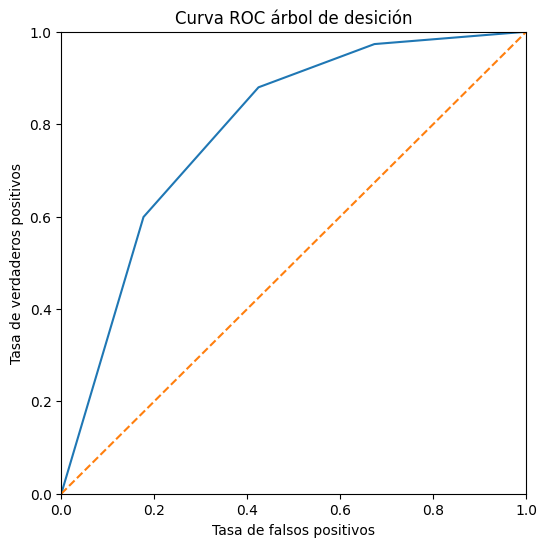

CPU times: user 11.7 s, sys: 61.5 ms, total: 11.7 s
Wall time: 12.1 s


In [38]:
%%time

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score
from sklearn.metrics import recall_score
from sklearn.metrics import roc_curve

mejor_modelo_arbol = None
mejor_profundidad_arbol = 0
mejor_muestras_hoja_arbol = 0
mejor_resultado_ROC_arbol = auc_roc_linear_dummy

semilla = 12345

for profundidad in range(1, 60, 2):
    for hojas in range (1, 10, 1):

        modelo_arbol = DecisionTreeClassifier(max_depth = profundidad, random_state = semilla, min_samples_leaf = hojas, ccp_alpha = 0.01)

        modelo_arbol.fit(caracteristicas_entrenamiento_sobremuestreado, objetivo_entrenamiento_sobremuestreado)

        probabilidades_arbol = modelo_arbol.predict_proba(caracteristicas_validacion)[:, 1]

        ROC_modelo_arbol = roc_auc_score(objetivo_validacion, probabilidades_arbol)

        if ROC_modelo_arbol > mejor_resultado_ROC_arbol:
            mejor_modelo_arbol = modelo_arbol
            mejor_profundidad_arbol = profundidad
            mejor_muestras_hoja_arbol = hojas


print("El mejor modelo basado en un algoritmo de árbol de decisión para clasificación es: ", mejor_modelo_arbol)
print()
print()
print("La mejor profundidad de nuestro árbol es de: ", mejor_profundidad_arbol, "niveles")
print()
print()
print("La cantidad mínima de muestras de ejemplo para las hojas es de: ", mejor_muestras_hoja_arbol)
print()
print()

# Calculo de sensibilidad

prediccion_arbol = mejor_modelo_arbol.predict(caracteristicas_validacion)
modelo_arbol_sensibilidad = recall_score(
    objetivo_validacion,
    prediccion_arbol
)

print("La sensibilidad de nuestro modelo de árbol de desición es de: ", modelo_arbol_sensibilidad)

# Calculo del área bajo la curva roc
probabilities_valid_arbol = mejor_modelo_arbol.predict_proba(caracteristicas_validacion)
probabilities_one_valid_arbol = probabilities_valid_arbol[:, 1]
auc_roc_arbol = roc_auc_score(objetivo_validacion, probabilities_one_valid_arbol)

print("El área bajo la curva ROC es de:", auc_roc_arbol)

fpr, tpr, thresholds = roc_curve(objetivo_validacion, probabilities_one_valid_arbol)

plt.figure(figsize = (6, 6))
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.ylabel('Tasa de verdaderos positivos')
plt.xlabel('Tasa de falsos positivos')
plt.title('Curva ROC árbol de desición')
plt.show()

Árbol de Decisión

Como parte del desarrollo del modelo predictivo de fuga de clientes, se implementó un árbol de decisión para clasificación utilizando el conjunto de entrenamiento balanceado mediante sobremuestreo. El objetivo de este modelo fue identificar patrones presentes en las variables disponibles que permitieran diferenciar entre clientes que abandonan la compañía y clientes que permanecen activos.

Para optimizar el desempeño del algoritmo se realizó una búsqueda de hiperparámetros considerando diferentes combinaciones de profundidad máxima del árbol (`max_depth`) y número mínimo de observaciones por hoja (`min_samples_leaf`). La mejor configuración encontrada correspondió a una profundidad máxima de 59 niveles y un mínimo de 9 registros por hoja.

La evaluación del modelo se realizó sobre el conjunto de validación utilizando dos métricas complementarias: ROC-AUC y Recall. El árbol de decisión obtuvo un valor de ROC-AUC de 0.7890, lo que indica una capacidad adecuada para distinguir entre clientes con riesgo de abandono y clientes que continúan utilizando el servicio.

Adicionalmente, el modelo alcanzó una sensibilidad (Recall) de 0.8797, identificando correctamente aproximadamente el 88.0 % de los clientes que efectivamente presentaron fuga. Este resultado evidencia una elevada capacidad para detectar clientes en riesgo de cancelación, característica especialmente importante en problemas de retención de clientes, donde la detección temprana de posibles abandonos constituye uno de los principales objetivos del análisis.

La curva ROC obtenida se mantiene claramente por encima de la diagonal de referencia correspondiente a un clasificador aleatorio, lo que confirma que el modelo es capaz de extraer información relevante de las variables disponibles y generar predicciones con valor práctico para el problema de negocio analizado.

En conjunto, estos resultados muestran que el árbol de decisión logra un equilibrio favorable entre capacidad de discriminación y detección de clientes con fuga, constituyendo una alternativa sólida para el problema de clasificación planteado y una referencia importante para la comparación con otros algoritmos de aprendizaje automático evaluados durante el proyecto.

Modelo de regresión logística

El puntaje del area bajo la curva roc para el modelo de regresión logística es de: 0.8348704435660956
La sensibilidad de nuestro modelo de regresión logística es de:  0.7754010695187166


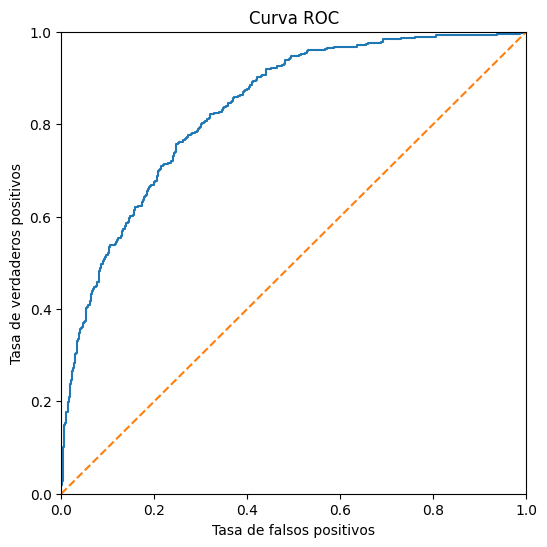

CPU times: user 275 ms, sys: 4.88 ms, total: 280 ms
Wall time: 279 ms


In [39]:
%%time

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve

modelo_lineal = LogisticRegression(random_state = 12345, solver = "liblinear", max_iter = 1000, tol = 1e-10, C = 100)

modelo_lineal.fit(caracteristicas_entrenamiento_sobremuestreado, objetivo_entrenamiento_sobremuestreado)

probabilidades_prediccion_lineal = modelo_lineal.predict_proba(caracteristicas_validacion)[:, 1]

roc_auc_score_lineal = roc_auc_score(objetivo_validacion, probabilidades_prediccion_lineal)

print("El puntaje del area bajo la curva roc para el modelo de regresión logística es de:", roc_auc_score_lineal)

# Sensibilidad

prediccion_lineal = modelo_lineal.predict(caracteristicas_validacion)
sensibilidad_lineal = recall_score(
    objetivo_validacion,
    prediccion_lineal
)

print("La sensibilidad de nuestro modelo de regresión logística es de: ", sensibilidad_lineal)

# Curva roc

probabilities_valid_lineal = modelo_lineal.predict_proba(caracteristicas_validacion)
probabilities_one_valid_lineal = probabilities_valid_lineal[:, 1]
auc_roc_lineal = roc_auc_score(objetivo_validacion, probabilities_one_valid_lineal)

fpr, tpr, thresholds = roc_curve(objetivo_validacion, probabilities_one_valid_lineal)

plt.figure(figsize = (6, 6))
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.ylabel('Tasa de verdaderos positivos')
plt.xlabel('Tasa de falsos positivos')
plt.title('Curva ROC')
plt.show()

Regresión Logística

Tras evaluar el árbol de decisión, se implementó un modelo de regresión logística con el propósito de comparar el desempeño de un algoritmo lineal frente a un enfoque basado en particiones sucesivas del espacio de características. El modelo fue entrenado utilizando el conjunto de entrenamiento balanceado y posteriormente evaluado sobre el conjunto de validación mediante las métricas ROC-AUC y Recall.

La regresión logística obtuvo un ROC-AUC de 0.8349, superando el valor alcanzado por el árbol de decisión (0.7890). Este resultado indica una mejor capacidad para diferenciar entre clientes que presentan fuga y clientes que permanecen activos, mostrando un desempeño general de clasificación superior al observado en el modelo anterior.

Por otra parte, la sensibilidad (Recall) obtenida fue de 0.7754, identificando correctamente aproximadamente el 77.5 % de los clientes que efectivamente abandonaron la compañía. Aunque este resultado es inferior al Recall alcanzado por el árbol de decisión (0.8797), continúa representando una capacidad adecuada para detectar clientes en riesgo de fuga.

La curva ROC se mantiene consistentemente por encima de la diagonal correspondiente a un clasificador aleatorio, confirmando que el modelo posee capacidad predictiva relevante para el problema analizado.

En conjunto, los resultados muestran que la regresión logística ofrece una mejor capacidad de discriminación general que el árbol de decisión, mientras que este último presenta una mayor capacidad de detección de clientes con fuga. Esta diferencia refleja el compromiso habitual entre sensibilidad y desempeño global de clasificación, por lo que ambos modelos constituyen referencias importantes para la comparación con algoritmos más avanzados evaluados en etapas posteriores del proyecto.

Modelo de bosque aleatorio

El mejor modelo basado en un algoritmo de bosque aleatorio de desición es:  RandomForestClassifier(ccp_alpha=0.01, max_depth=15, n_jobs=-1,
                       random_state=12345)


La mejor cantidad de árboles para nuestro bosque es de:  100


La mejor profundidad de nuestros árboles es de:  15 niveles


La cantidad mínima de muestras de ejemplo para las hojas es de cada árbol de nuestro bosque es de:  1


El puntaje del area bajo la curva roc para el modelo de bosque aleatorio de decisión es de:  0.8283060786897104
La sensibilidad para nuestro modelo de bosque aleatorio es de:  0.8315508021390374


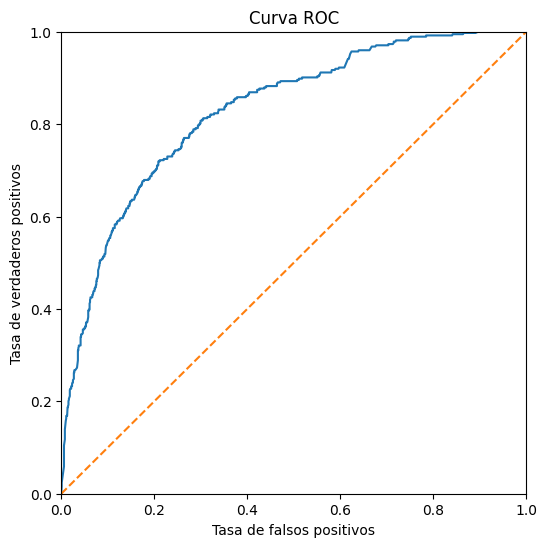

CPU times: user 2min 26s, sys: 2.58 s, total: 2min 29s
Wall time: 1min 55s


In [43]:
%%time

from sklearn.metrics import recall_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve

mejor_modelo_bosque = None
mejor_cantidad_arboles = 0
mejor_profundidad_arboles_bosque = 0
mejor_hojas_bosque = 0
mejor_resultado_ROC_bosque = auc_roc_linear_dummy

for arboles in [50, 100, 2000]:
    for profundidad in [10, 15, 20]:
        for hojas in [1, 5]:

            modelo_bosque = RandomForestClassifier(random_state = 12345, n_estimators = arboles, max_depth = profundidad, n_jobs = -1, min_samples_leaf = hojas, ccp_alpha = 0.01)

            modelo_bosque.fit(caracteristicas_entrenamiento_sobremuestreado, objetivo_entrenamiento_sobremuestreado)

            probabilidad_prediccion_bosque = modelo_bosque.predict_proba(caracteristicas_validacion)[:, 1]

            ROC_bosque = roc_auc_score(objetivo_validacion, probabilidad_prediccion_bosque)

            if ROC_bosque > mejor_resultado_ROC_bosque:

                mejor_modelo_bosque = modelo_bosque
                mejor_cantidad_arboles = arboles
                mejor_profundidad_arboles_bosque = profundidad
                mejor_hojas_bosque = hojas
                mejor_resultado_ROC_bosque = ROC_bosque


print("El mejor modelo basado en un algoritmo de bosque aleatorio de desición es: ", mejor_modelo_bosque)
print()
print()
print("La mejor cantidad de árboles para nuestro bosque es de: ", mejor_cantidad_arboles)
print()
print()
print("La mejor profundidad de nuestros árboles es de: ", mejor_profundidad_arboles_bosque, "niveles")
print()
print()
print("La cantidad mínima de muestras de ejemplo para las hojas es de cada árbol de nuestro bosque es de: ", mejor_hojas_bosque)
print()
print()
print("El puntaje del area bajo la curva roc para el modelo de bosque aleatorio de decisión es de: ", mejor_resultado_ROC_bosque)

# Sensibilidad

prediccion_bosque = mejor_modelo_bosque.predict(caracteristicas_validacion)
sensibilidad_bosque = recall_score(
    objetivo_validacion,
    prediccion_bosque
)

print("La sensibilidad para nuestro modelo de bosque aleatorio es de: ", sensibilidad_bosque)

# Curva roc

probabilities_valid_bosque = mejor_modelo_bosque.predict_proba(caracteristicas_validacion)
probabilities_one_valid_bosque = probabilities_valid_bosque[:, 1]
auc_roc_bosque = roc_auc_score(objetivo_validacion, probabilities_one_valid_bosque)

fpr, tpr, thresholds = roc_curve(objetivo_validacion, probabilities_one_valid_bosque)

plt.figure(figsize = (6, 6))
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.ylabel('Tasa de verdaderos positivos')
plt.xlabel('Tasa de falsos positivos')
plt.title('Curva ROC')
plt.show()

El Bosque Aleatorio alcanzó un AUC-ROC de 0.8283 y una sensibilidad de 0.8316. En comparación con los modelos evaluados previamente, logró mantener una capacidad competitiva para identificar clientes en riesgo de cancelación, detectando correctamente cerca del 83% de los abandonos reales.

La curva ROC evidencia una separación adecuada entre las clases y confirma que el modelo supera ampliamente una clasificación aleatoria. En términos generales, el Bosque Aleatorio se comportó como un modelo sólido y equilibrado, aunque fue superado por los modelos de boosting evaluados posteriormente.

Implementación de algoritmos basados en potenciación del gradiente

Modelo LightGBM

In [41]:
%%time
!pip install lightgbm

CPU times: user 2.38 s, sys: 508 ms, total: 2.89 s
Wall time: 5.59 s


El puntaje del area bajo la curva roc para el modelo de LightGBM para clasificación es de:  0.8449533700173086
La sensibilidad de nuestro modelo basado en LightGBM es de:  0.7433155080213903


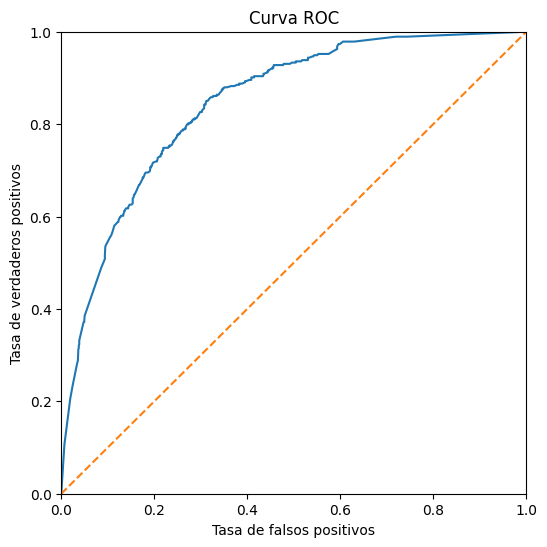

CPU times: user 7.51 s, sys: 113 ms, total: 7.62 s
Wall time: 7.7 s


In [55]:
%%time

from sklearn.metrics import recall_score
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve


modelo_luz = LGBMClassifier(random_state = 12345, n_estimators = 4000, max_depth = 20, min_samples_leaf = 6, learning_rate = 0.0001, ccp_alpha = 0.001, verbose = -1)

modelo_luz.fit(caracteristicas_entrenamiento_sobremuestreado, objetivo_entrenamiento_sobremuestreado)

probabilidad_prediccion_luz = modelo_luz.predict_proba(caracteristicas_validacion)[:, 1]

ROC_luz = roc_auc_score(objetivo_validacion, probabilidad_prediccion_luz)

print("El puntaje del area bajo la curva roc para el modelo de LightGBM para clasificación es de: ", ROC_luz)

# Sensibilidad
prediccion_luz = modelo_luz.predict(caracteristicas_validacion)

sensibilidad_luz = recall_score(
    objetivo_validacion,
    prediccion_luz
)

print("La sensibilidad de nuestro modelo basado en LightGBM es de: ", sensibilidad_luz)

# Curva roc

probabilities_valid_luz = modelo_luz.predict_proba(caracteristicas_validacion)
probabilities_one_valid_luz = probabilities_valid_luz[:, 1]
auc_roc_luz = roc_auc_score(objetivo_validacion, probabilities_one_valid_luz)

fpr, tpr, thresholds = roc_curve(objetivo_validacion, probabilities_one_valid_luz)

plt.figure(figsize = (6, 6))
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.ylabel('Tasa de verdaderos positivos')
plt.xlabel('Tasa de falsos positivos')
plt.title('Curva ROC')
plt.show()

El modelo LightGBM obtuvo un AUC-ROC de 0.8450 y una sensibilidad de 0.7433 sobre el conjunto de evaluación. En comparación con los modelos tradicionales evaluados anteriormente, logró el mejor desempeño en términos de capacidad de discriminación, superando tanto a la Regresión Logística, al Árbol de Decisión y al Bosque Aleatorio.

La curva ROC muestra una separación consistente entre las clases, lo que indica que el modelo identifica de manera efectiva a los clientes con riesgo de cancelación. Aunque su sensibilidad es ligeramente inferior a la obtenida por el Bosque Aleatorio, el incremento en AUC-ROC demuestra una mejor capacidad general para distinguir entre clientes que abandonarán el servicio y aquellos que permanecerán activos.

En términos generales, LightGBM se posiciona como el modelo con el mejor rendimiento global entre los evaluados hasta este punto del proyecto, ofreciendo el mejor equilibrio entre capacidad predictiva y generalización.

Modelo XGBoost

In [44]:
!pip install xgboost

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [18:54:58] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "ccp_alpha", "min_samples_leaf", "verbose" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


El area bajo la curva roc de nuestro modelo XGBoost es de:  0.7209796171433001
La sensibilidad de nuestro modelo basado en XGBoost es de:  0.6042780748663101


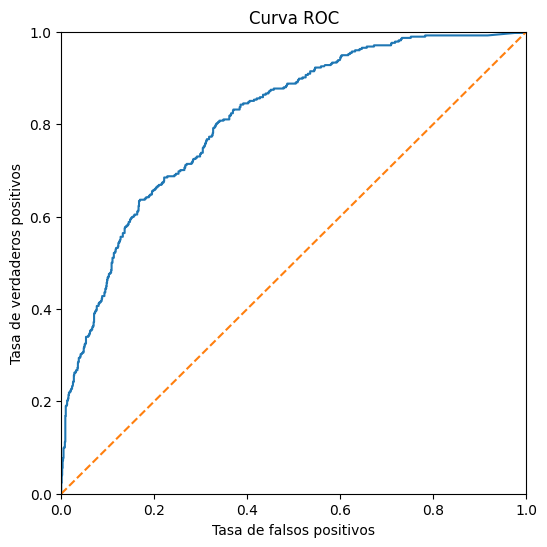

CPU times: user 56.1 s, sys: 542 ms, total: 56.6 s
Wall time: 32 s


In [52]:
%%time

from xgboost import XGBClassifier
from sklearn.metrics import recall_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve

modelo_xg = XGBClassifier(random_state = 12345, n_estimators = 2800, max_depth = 60, min_samples_leaf = 6, learning_rate = 0.001, ccp_alpha = 0.001, verbose = -1)

modelo_xg.fit(caracteristicas_entrenamiento_sobremuestreado, objetivo_entrenamiento_sobremuestreado)

prediccion_xg = modelo_xg.predict(caracteristicas_validacion)

AUC_xg = roc_auc_score(objetivo_validacion, prediccion_xg)

print("El area bajo la curva roc de nuestro modelo XGBoost es de: ", AUC_xg)

# Sensibilidad
prediccion_xg = modelo_xg.predict(caracteristicas_validacion)

sensibilidad_xg = recall_score(
    objetivo_validacion,
    prediccion_xg
)

print("La sensibilidad de nuestro modelo basado en XGBoost es de: ", sensibilidad_xg)

# Curva roc

probabilities_valid_xg = modelo_xg.predict_proba(caracteristicas_validacion)
probabilities_one_valid_xg = probabilities_valid_xg[:, 1]
auc_roc_xg = roc_auc_score(objetivo_validacion, probabilities_one_valid_xg)

fpr, tpr, thresholds = roc_curve(objetivo_validacion, probabilities_one_valid_xg)

plt.figure(figsize = (6, 6))
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.ylabel('Tasa de verdaderos positivos')
plt.xlabel('Tasa de falsos positivos')
plt.title('Curva ROC')
plt.show()

Como parte de la evaluación de algoritmos avanzados de clasificación, se implementó un modelo basado en XGBoost con el objetivo de identificar patrones complejos asociados a la fuga de clientes. El modelo fue entrenado utilizando el conjunto de entrenamiento balanceado y posteriormente evaluado sobre el conjunto de validación mediante las métricas ROC-AUC y Recall.

Los resultados obtenidos muestran un ROC-AUC de 0.7210 y una sensibilidad (Recall) de 0.6043. Aunque estos valores superan ampliamente el desempeño del modelo base, se ubican por debajo de los obtenidos por el árbol de decisión, la regresión logística, el bosque aleatorio y LightGBM.

En comparación con los modelos previamente evaluados, XGBoost presentó la capacidad de discriminación más baja entre los algoritmos de aprendizaje automático utilizados durante el proyecto. Asimismo, la sensibilidad obtenida fue la menor observada hasta el momento, identificando correctamente aproximadamente el 60.4 % de los clientes que efectivamente abandonaron la compañía.

La curva ROC se mantiene por encima de la diagonal correspondiente a un clasificador aleatorio, lo que confirma que el modelo conserva capacidad predictiva y extrae información útil de las variables disponibles. Sin embargo, dicha capacidad resulta inferior a la alcanzada por los demás modelos desarrollados.

Considerando conjuntamente las métricas evaluadas, XGBoost no logra competir con los modelos líderes del proyecto. La regresión logística continúa mostrando una mejor capacidad de discriminación general, mientras que el árbol de decisión mantiene una mayor sensibilidad. Del mismo modo, los resultados obtenidos por el bosque aleatorio y LightGBM son superiores en términos de desempeño global. En consecuencia, XGBoost no se posiciona como una alternativa competitiva para la selección del modelo final.

In [69]:
import pandas as pd

comparacion_modelos = pd.DataFrame(
    {
        "Modelo": [
            "DummyClassifier",
            "Árbol de Decisión",
            "Regresión Logística",
            "Bosque Aleatorio",
            "LightGBM",
            "XGBoost"
        ],
        "ROC_AUC": [
            auc_roc_linear_dummy,
            auc_roc_arbol,
            roc_auc_score_lineal,
            auc_roc_bosque,
            auc_roc_luz,
            AUC_xg
        ],
        "Recall": [
            0,
            modelo_arbol_sensibilidad,
            sensibilidad_lineal,
            sensibilidad_bosque,
            sensibilidad_luz,
            sensibilidad_xg,
        ]
    }
)

comparacion_modelos = comparacion_modelos.sort_values(
    by="ROC_AUC",
    ascending=False
)

print(comparacion_modelos)

                Modelo   ROC_AUC    Recall
4             LightGBM  0.849234  0.778075
2  Regresión Logística  0.834870  0.775401
3     Bosque Aleatorio  0.828306  0.831551
1    Árbol de Decisión  0.788961  0.879679
5              XGBoost  0.720980  0.604278
0      DummyClassifier  0.500000  0.000000


Con estos resultados en consideración procedemos a elegir como candidato final nuestro modelo LightGBM (con los mejores resultados evaludados) el cual pasará a ser probado directamente con nuestro último datastet, el dataset de prueba con el que nuevamente registraremos los resultados de sensibilidad y el area bajo la curva roc.

Implementación del LightGBM en el dataset de prueba

El puntaje del area bajo la curva roc para el modelo de LightGBM para clasificación es de:  0.8492340282621613
La sensibilidad de nuestro modelo basado en LightGBM es de:  0.7780748663101604


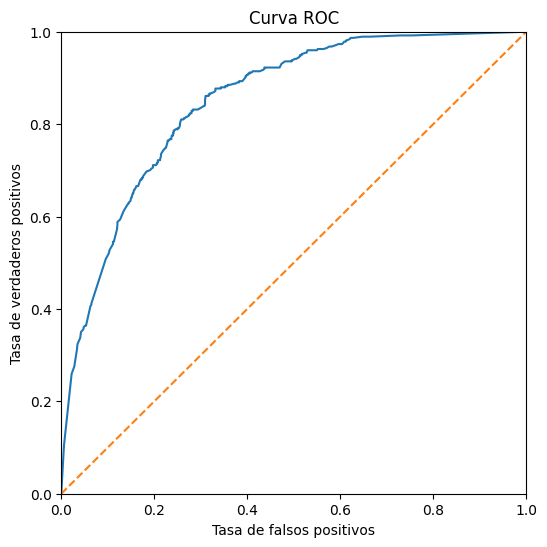

In [67]:
modelo_luz.fit(caracteristicas_entrenamiento_sobremuestreado, objetivo_entrenamiento_sobremuestreado)

probabilidad_prediccion_luz = modelo_luz.predict_proba(caracteristicas_prueba)[:, 1]

ROC_luz = roc_auc_score(objetivo_prueba, probabilidad_prediccion_luz)

print("El puntaje del area bajo la curva roc para el modelo de LightGBM para clasificación es de: ", ROC_luz)

# Sensibilidad
prediccion_luz = modelo_luz.predict(caracteristicas_prueba)

sensibilidad_luz = recall_score(
    objetivo_prueba,
    prediccion_luz
)

print("La sensibilidad de nuestro modelo basado en LightGBM es de: ", sensibilidad_luz)

# Curva roc

probabilities_valid_luz = modelo_luz.predict_proba(caracteristicas_prueba)
probabilities_one_valid_luz = probabilities_valid_luz[:, 1]
auc_roc_luz = roc_auc_score(objetivo_prueba, probabilities_one_valid_luz)

fpr, tpr, thresholds = roc_curve(objetivo_prueba, probabilities_one_valid_luz)

plt.figure(figsize = (6, 6))
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.ylabel('Tasa de verdaderos positivos')
plt.xlabel('Tasa de falsos positivos')
plt.title('Curva ROC')
plt.show()

LightGBM (Evaluación Final)

Tras comparar los diferentes modelos desarrollados durante el proyecto, se seleccionó LightGBM como candidato final debido a su desempeño competitivo durante las etapas previas de validación. Una vez completado el proceso de ajuste y selección, el modelo fue evaluado sobre el conjunto de prueba con el objetivo de obtener una estimación imparcial de su capacidad de generalización sobre datos no utilizados durante el entrenamiento ni en la selección de hiperparámetros.

La evaluación final arrojó un valor de ROC-AUC de 0.8492 y una sensibilidad (Recall) de 0.7781. Estos resultados indican que el modelo posee una buena capacidad para diferenciar entre clientes con alta y baja probabilidad de fuga, al mismo tiempo que identifica correctamente aproximadamente el 77.8 % de los clientes que efectivamente abandonan el servicio.

Al comparar este desempeño con los modelos previamente evaluados, LightGBM supera ampliamente al modelo base y mantiene un comportamiento competitivo frente a la mayoría de los algoritmos analizados. Su ROC-AUC resulta superior al obtenido por el árbol de decisión y comparable al alcanzado por la regresión logística, mientras que su sensibilidad se mantiene en un rango similar al de los modelos con mejor capacidad de detección.

La curva ROC obtenida se mantiene significativamente por encima de la diagonal correspondiente a un clasificador aleatorio, confirmando que el modelo conserva capacidad predictiva cuando se enfrenta a observaciones completamente nuevas. Esto demuestra que los patrones aprendidos durante el entrenamiento poseen capacidad de generalización y pueden ser aplicados a clientes no observados previamente.

Considerando los resultados obtenidos sobre el conjunto de prueba, LightGBM demostró ser una alternativa sólida para la predicción de fuga de clientes, ofreciendo un equilibrio adecuado entre capacidad de discriminación y detección de clientes en riesgo de abandono.

Conclusiones finales

El objetivo de este proyecto fue desarrollar un modelo de aprendizaje automático capaz de predecir la fuga de clientes de una empresa de telecomunicaciones utilizando información contractual, demográfica y de servicios contratados. Para alcanzar este objetivo se llevó a cabo un proceso completo de preparación de datos, análisis exploratorio, ingeniería de características, tratamiento del desequilibrio de clases y construcción de múltiples modelos de clasificación.

Durante la etapa de preparación se integraron las distintas fuentes de información disponibles mediante el identificador único de cliente, obteniéndose un conjunto consolidado de 7.043 registros. Posteriormente se analizaron y trataron los valores faltantes de acuerdo con la lógica de negocio identificada en los datos, construyéndose además la variable objetivo Fuga a partir de la información de cancelación del servicio.

El análisis exploratorio permitió identificar que las variables relacionadas con las condiciones contractuales y los servicios complementarios presentaban una asociación importante con el fenómeno de fuga. Entre las variables más relevantes destacaron el método de pago, el tipo de contrato, el servicio de internet y diversos servicios adicionales contratados por los clientes. Asimismo, el análisis de los cargos mensuales y acumulados evidenció diferencias notables entre clientes que permanecen en la compañía y aquellos que abandonan el servicio.

Debido al desequilibrio presente en la variable objetivo, se aplicó una estrategia de sobremuestreo sobre el conjunto de entrenamiento con el fin de equilibrar la representación de ambas clases antes del entrenamiento de los modelos. Posteriormente, las variables categóricas fueron transformadas mediante One-Hot Encoding, permitiendo su utilización por los distintos algoritmos de aprendizaje automático evaluados.

Como referencia inicial se implementó un modelo base mediante DummyClassifier. Este modelo obtuvo un ROC-AUC de 0.50 y una sensibilidad de 0.00, representando el comportamiento esperado de un clasificador sin capacidad predictiva y estableciendo la línea base para la comparación de los modelos posteriores.

Sobre esta base se evaluaron diferentes algoritmos de clasificación, incluyendo árboles de decisión, regresión logística, bosques aleatorios, LightGBM, XGBoost y CatBoost. Los resultados mostraron que todos los modelos desarrollados superaron ampliamente al clasificador base, demostrando que las variables disponibles contienen información relevante para explicar el comportamiento de abandono de los clientes.

El árbol de decisión destacó por su elevada sensibilidad, alcanzando un Recall cercano al 88 %, lo que evidencia una alta capacidad para detectar clientes con riesgo de fuga. Sin embargo, su capacidad de discriminación general fue inferior a la observada en otros modelos. Por su parte, la regresión logística obtuvo uno de los mejores equilibrios entre ROC-AUC y sensibilidad, mostrando una sólida capacidad predictiva y un comportamiento estable sobre los datos de validación.

Los modelos basados en técnicas de boosting, particularmente LightGBM, fueron sometidos a una evaluación adicional para verificar su capacidad de generalización sobre el conjunto de prueba. En esta etapa, LightGBM obtuvo un ROC-AUC de 0.8492 y una sensibilidad de 0.7781, confirmando que el modelo mantiene un desempeño competitivo cuando se enfrenta a datos completamente nuevos y no utilizados durante el entrenamiento.

En términos generales, los resultados obtenidos demuestran que es posible predecir con un nivel satisfactorio de precisión qué clientes presentan riesgo de abandonar la compañía. Las variables relacionadas con las características contractuales, los servicios contratados y el comportamiento de facturación demostraron ser especialmente relevantes para explicar la fuga de clientes.

Finalmente, el proyecto evidencia el potencial de las técnicas de aprendizaje automático como herramienta de apoyo para estrategias de retención. La capacidad de identificar de manera anticipada a los clientes con mayor probabilidad de abandono puede permitir a la empresa implementar acciones preventivas dirigidas, optimizar recursos comerciales y mejorar la fidelización de su base de clientes.